In [1]:
!pip install numpy==1.26.4 --force-reinstall --quiet


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 96.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cupy-cuda12x 14.0.1 requires numpy<2.6,>=2.0, but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
jaxlib 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
shap 0.51.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
rasterio 1.5.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
xarray-einstats 0.10.0 requires numpy>=2.0, but you have numpy 1.26.4 whic

In [ ]:
# ✅ Step 2.1: Install PyTorch and torchvision first
!pip install torch==2.2.2 torchvision==0.17.2 --quiet

# ✅ Step 2.2: Install compatible RealESRGAN ecosystem
!pip install basicsr==1.4.2 gfpgan==1.3.8 realesrgan==0.3.0 facexlib==0.3.0 --quiet

# ✅ Step 2.3: Install compatible numpy
!pip install numpy==1.26.4 --force-reinstall --quiet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 755.6/755.6 MB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 125.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 119.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 98.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 53.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.7/731.7 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2/124.2 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.0/196.0 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
# ✅ Patch basicsr to fix bad torchvision import
!sed -i "s/from torchvision.transforms.functional_tensor import rgb_to_grayscale/from torchvision.transforms.functional import rgb_to_grayscale/" /usr/local/lib/python*/dist-packages/basicsr/data/degradations.py


✅ Image downloaded


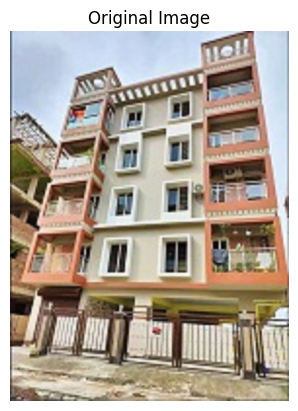

In [ ]:
# ✅ Step 4.1: Download the image
import requests
from PIL import Image
import matplotlib.pyplot as plt
import os

img_url = 'https://liveprojectscare.com/Emit/wp-content/uploads/2025/04/dasfaes-a-daw-dasd.jpg'
img_path = 'low_res.jpg'

headers = {
    'User-Agent': 'Mozilla/5.0',
    'Accept': 'image/avif,image/webp,image/apng,image/*,*/*;q=0.8'
}

response = requests.get(img_url, headers=headers)
if response.status_code == 200:
    with open(img_path, 'wb') as f:
        f.write(response.content)
    print("✅ Image downloaded")
else:
    raise Exception(f"❌ Failed to download image. Status code: {response.status_code}")

# ✅ Step 4.2: Display original image
original = Image.open(img_path).convert("RGB")
plt.imshow(original)
plt.axis('off')
plt.title("Original Image")
plt.show()
